In [2]:
import matplotlib.pyplot as plt
import numpy as np

days = np.arange(0, 240)
print(days.shape)
trend = days * 0.05
print(trend.shape)

(240,)
(240,)


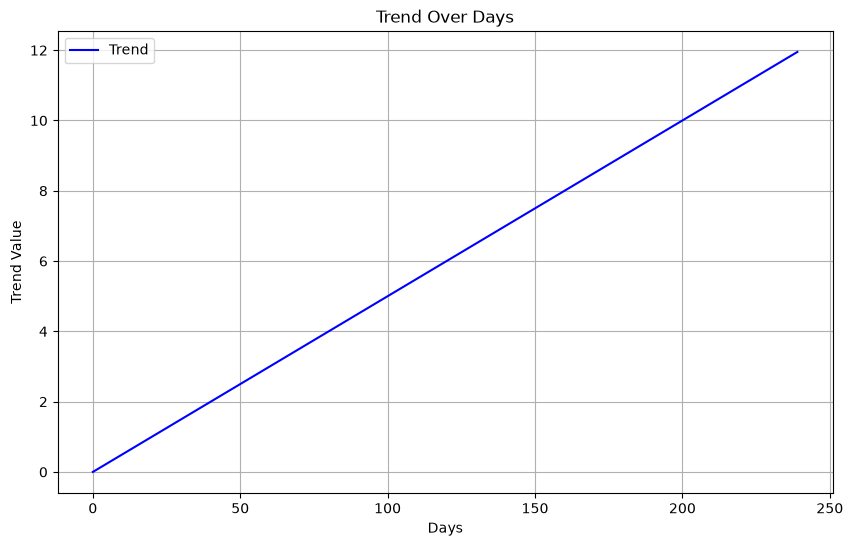

In [3]:
plt.figure(figsize=(10, 6))
plt.plot(days, trend, label='Trend', color='blue')
plt.title('Trend Over Days')
plt.xlabel('Days')
plt.ylabel('Trend Value')
plt.legend()
plt.grid()
plt.show()

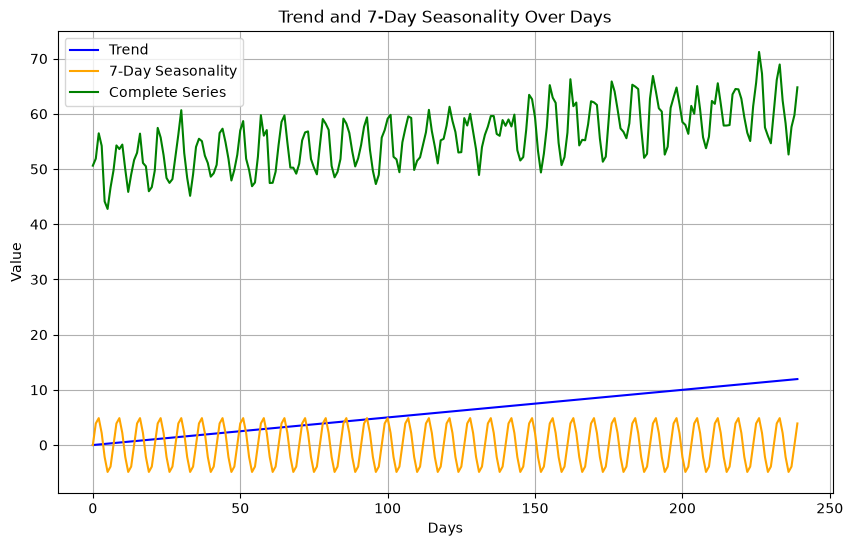

In [10]:
rng = np.random.default_rng(seed=42)
noise = rng.normal(0, 2, len(days))

seasonality = 5 * np.sin(2*(np.pi / 7) * days)
level = 50
series = level + trend + seasonality + noise
plt.figure(figsize=(10, 6))
plt.plot(days, trend, label='Trend', color='blue')
plt.plot(days, seasonality, label='7-Day Seasonality', color='orange')
plt.plot(days, series, label='Complete Series', color='green')
plt.title('Trend and 7-Day Seasonality Over Days')
plt.xlabel('Days')
plt.ylabel('Value')
plt.legend()
plt.grid()
plt.show()

ourbe verte présente maintenant trois comportements :
- Une tendance croissante : les valeurs augmentent progressivement au fil des jours.
- Une saisonnalité : les oscillations se répètent environ tous les sept jours.
- Des fluctuations irrégulières : les pics et les creux ne sont plus parfaitement réguliers à cause du bruit.

Training set: (192,), (192,)
Test set: (48,), (48,)


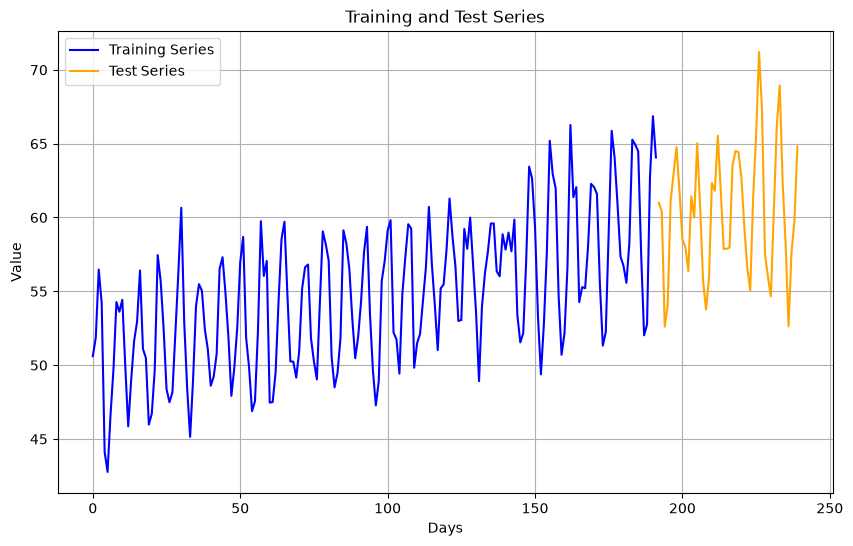

In [ ]:
idx_80 =  int(len(days) * 0.8)
train_days = days[:idx_80]
train_series = series[:idx_80]
test_days = days[idx_80:]
test_series = series[idx_80:]
print(f"Training set: {train_days.shape}, {train_series.shape}")
print(f"Test set: {test_days.shape}, {test_series.shape}")
plt.figure(figsize=(10, 6))
plt.plot(train_days, train_series, label='Training Series', color='blue')
plt.plot(test_days, test_series, label='Test Series', color='orange')
plt.title('Training and Test Series')
plt.xlabel('Days')
plt.ylabel('Value')
plt.legend()
plt.grid()
plt.show()

In [15]:

baseline_predictions = [series[t - 7] for t in test_days]
print(f"Baseline predictions: {baseline_predictions[:5]}")
print(len(baseline_predictions))
print(len(test_series))

Baseline predictions: [np.float64(64.49093067957983), np.float64(57.497050178856114), np.float64(52.02642237564989), np.float64(52.7545241891685), np.float64(62.75185586446243)]
48
48


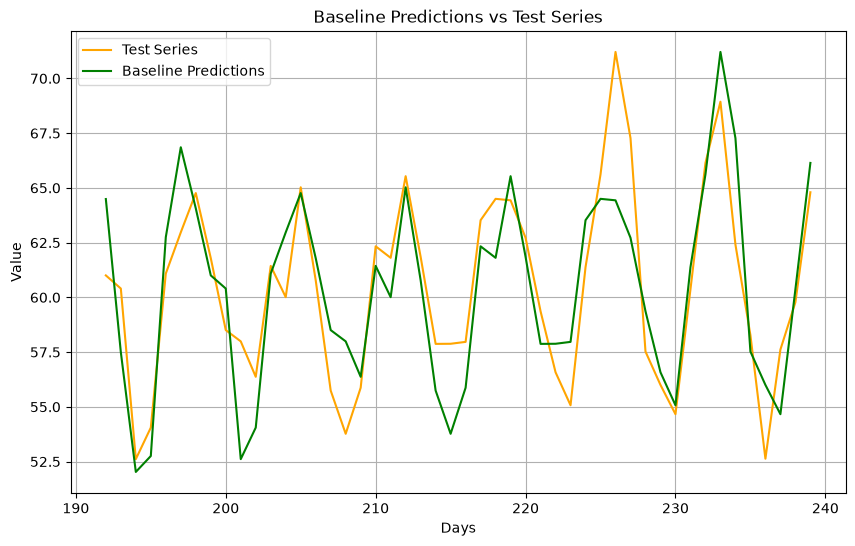

In [16]:
plt.figure(figsize=(10, 6))
plt.plot(test_days, test_series, label='Test Series', color='orange')
plt.plot(test_days, baseline_predictions, label='Baseline Predictions', color='green')
plt.title('Baseline Predictions vs Test Series')
plt.xlabel('Days')
plt.ylabel('Value')
plt.legend()
plt.grid()
plt.show()

In [18]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(test_series, baseline_predictions)
print(f"Mean Absolute Error of Baseline Predictions: {mae:.4f}")
mse = mean_squared_error(test_series, baseline_predictions)
print(f"Mean Squared Error of Baseline Predictions: {mse:.4f}")

Mean Absolute Error of Baseline Predictions: 2.0047
Mean Squared Error of Baseline Predictions: 6.2230


In [19]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Construire les caractéristiques retardées
lags = [1, 2, 7]

X = np.array([
    [series[t - lag] for lag in lags]
    for t in range(7, len(series))
])

y = series[7:]

# Découpage chronologique (jour 192)
X_train = X[:192 - 7]
X_test = X[192 - 7:]

y_train = y[:192 - 7]
y_test = y[192 - 7:]

# Entraîner une régression linéaire
model = LinearRegression()
model.fit(X_train, y_train)

# Prédictions sur les 48 derniers jours
predictions = model.predict(X_test)

# Évaluation
reg_mae = mean_absolute_error(y_test, predictions)
reg_mse = mean_squared_error(y_test, predictions)

print(f"Regression MAE : {reg_mae:.4f}")
print(f"Regression MSE : {reg_mse:.4f}")

Regression MAE : 1.8738
Regression MSE : 5.1736


In [20]:
print("COMPARAISON DES MODÈLES")
print("-" * 42)

print(f"{'Modèle':<22} {'MAE':>8} {'MSE':>8}")
print(f"{'Baseline saisonnière':<22} {mae:>8.4f} {mse:>8.4f}")
print(f"{'Régression avec lags':<22} {reg_mae:>8.4f} {reg_mse:>8.4f}")

COMPARAISON DES MODÈLES
------------------------------------------
Modèle                      MAE      MSE
Baseline saisonnière     2.0047   6.2230
Régression avec lags     1.8738   5.1736


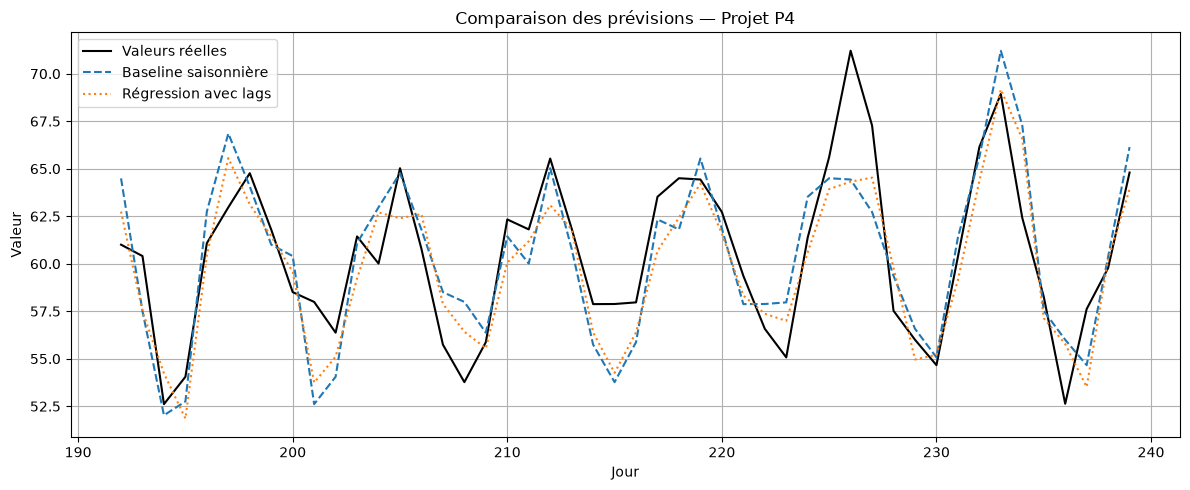

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(test_days, test_series,
         label="Valeurs réelles", color="black")

plt.plot(test_days, baseline_predictions,
         label="Baseline saisonnière", linestyle="--")

plt.plot(test_days, predictions,
         label="Régression avec lags", linestyle=":")

plt.title("Comparaison des prévisions — Projet P4")
plt.xlabel("Jour")
plt.ylabel("Valeur")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()